In [1]:
from tbparse import SummaryReader
import seaborn as sns
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
from tensorboard.backend.event_processing import event_accumulator
from pathlib import Path
import os
from tqdm import tqdm
from matplotlib.ticker import PercentFormatter, FuncFormatter
import glob
from concurrent.futures import ProcessPoolExecutor
from tensorboard.backend.event_processing.event_file_loader import EventFileLoader
from tensorboard.util import tensor_util
from tb_loader import load_file
from scipy.stats import ttest_ind, false_discovery_control

In [2]:
IMPORTANT_STATS = [
    "reward/mean",
    "observation/progress_per_second",
    "observation/forward_velocity",
    "collision/per_progress_metres",
    "collision/per_episode",
    "collision/per_step",
    "observation/progress_metres",
]

MOST_IMPORTANT_STATS = [
    "observation/progress_metres",
    "collision/per_progress_metres"
]

In [3]:
def load_runs(logdir="runs", tags=None):
    tags = set(tags) if tags is not None else None
    jobs = []
    for model_name in os.listdir(logdir):
      for f in sorted(glob.glob(f"{logdir}/{model_name}/**/*tfevents*", recursive=True)):
          jobs.append((f, model_name, tags))

    with ProcessPoolExecutor() as pool:
        return pd.concat(pool.map(load_file, jobs), ignore_index=True)
                                 # all tags
if os.path.exists("results/tensorboard_data.pkl"):
    df = pd.read_pickle("results/tensorboard_data.pkl")
else:
    df = load_runs(tags=IMPORTANT_STATS)        # only these


In [4]:
data = df

In [5]:
data.rename(columns={"dir_name": "run_name"}, inplace=True)
data["run_category"] = data["run_name"].str.split("_").str[:-2].str.join("_")
data["run_seed"] = data["run_name"].str.split("_").str[-1]
data["aux_weight"] = data["run_name"].str.split("_").str[-2].str[1:]
data = data.sort_values("wall_time").drop_duplicates(["run_name", "step", "tag"], keep="last")
data = data.sort_values("step")

In [6]:
data_pivot = data.pivot(index=["step", "run_category", "run_seed", "aux_weight"], columns="tag", values="value")
data_pivot["collision/per_progress_metres"] = data_pivot["collision/per_step"] / data_pivot["observation/progress_metres"]
data_pivot["observation/progress_per_second"] = data_pivot["observation/progress_metres"] * 25
data_pivot = data_pivot.reset_index()
data_pivot = data_pivot[~data_pivot["run_category"].str.startswith("rnn_")]
data_pivot

tag,step,run_category,run_seed,aux_weight,collision/per_episode,collision/per_step,observation/forward_velocity,observation/progress_metres,reward/mean,collision/per_progress_metres,observation/progress_per_second
0,0.0,all,s0,0.1,1.000000,0.001139,0.055985,0.002144,0.000996,0.531435,0.053597
1,0.0,all,s0,0.3,1.000000,0.000977,0.053421,0.001959,0.000972,0.498418,0.048983
2,0.0,all,s0,1,1.000000,0.000977,0.055088,0.002069,0.001084,0.471998,0.051725
3,0.0,all,s1,0.1,1.000000,0.001628,-0.025569,-0.000988,-0.002604,-1.646567,-0.024712
4,0.0,all,s1,0.3,1.000000,0.001058,-0.024407,-0.000804,-0.001854,-1.315935,-0.020099
...,...,...,...,...,...,...,...,...,...,...,...
124706,599.0,wheel_slip_rear_lateral,s1,0.3,0.181818,0.000163,4.078908,0.176673,0.176496,0.000921,4.416823
124707,599.0,wheel_slip_rear_lateral,s1,1,0.955224,0.005208,2.111820,0.086378,0.080987,0.060297,2.159441
124708,599.0,wheel_slip_rear_lateral,s2,0.1,0.461538,0.000977,3.464558,0.148024,0.146979,0.006597,3.700590
124709,599.0,wheel_slip_rear_lateral,s2,0.3,0.750000,0.000977,1.843529,0.078133,0.077074,0.012499,1.953328


In [7]:

RUN_COLUMNS = ["run_category", "run_seed", "aux_weight"]

In [8]:
auc_df = (
    data_pivot.sort_values("step")
    .groupby(RUN_COLUMNS)[IMPORTANT_STATS + ["step"]]
    .apply(lambda g: pd.Series(
        np.trapezoid(g[IMPORTANT_STATS].to_numpy(), g["step"].to_numpy(), axis=0),
        index=IMPORTANT_STATS,
    ))
)
auc_df = auc_df.reset_index()

last_50 = data_pivot.sort_values("step").groupby(RUN_COLUMNS).tail(50)
last_50_means = last_50.groupby(RUN_COLUMNS)[IMPORTANT_STATS].mean()
last_50_means["collision/per_progress_metres"] = (
    last_50_means["collision/per_step"] / last_50_means["observation/progress_metres"]
)
last_50_means["observation/progress_per_second"] = last_50_means["observation/progress_metres"] * 25
last_50_means = last_50_means[IMPORTANT_STATS].reset_index()

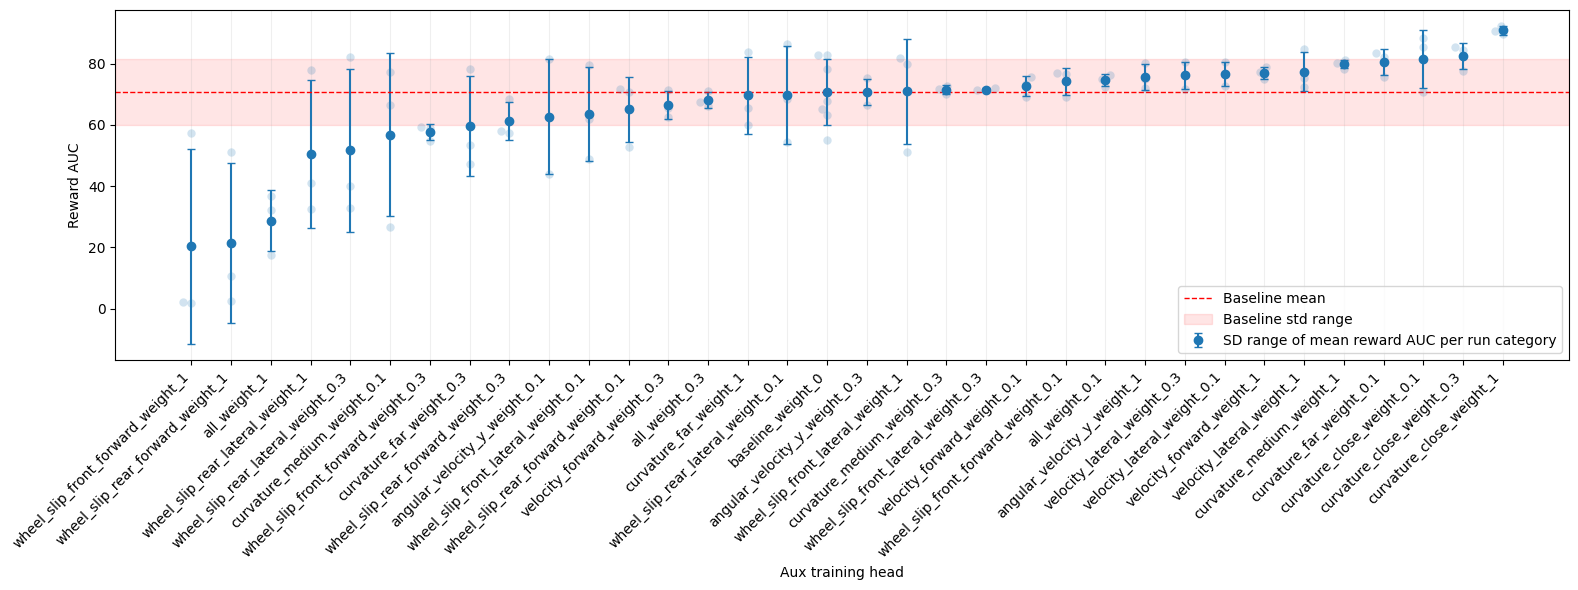

In [9]:
STAT = "reward/mean"

to_show = auc_df.sort_values(STAT)

to_show["label"] = to_show["run_category"] + \
    "_weight_" + to_show["aux_weight"].astype(str)

to_show_means = to_show.groupby(
    "label")[STAT].agg(["mean", "std"]).reset_index().sort_values("mean")

base_mean = to_show[to_show["run_category"] == "baseline"][STAT].mean()
base_std = to_show_means[to_show_means["label"].str.contains("baseline")]["std"].mean()

order = to_show_means["label"].tolist()

plt.figure(figsize=(16, 6))

plt.errorbar(
    to_show_means["label"],
    to_show_means["mean"],
    yerr=to_show_means["std"],
    fmt="o",
    capsize=3,
    label="SD range of mean reward AUC per run category"
)
sns.swarmplot(
    data=to_show,
    x="label",
    y=STAT,
    order=order,
    legend=False,
    s=6,
    alpha=0.2
).set(xlabel="Aux training head", ylabel="Reward AUC")

sns.scatterplot(
    data=to_show_means,
    x="label",
    y="mean"
)

plt.grid(True, axis="x", alpha=0.2)

plt.axhline(base_mean, color="red", ls="--", lw=1, label="Baseline mean")
plt.axhspan(base_mean - base_std, base_mean + base_std,
            color="red", alpha=0.1, label="Baseline std range")

plt.xticks(rotation=45, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("results/figures/auc_comparison.pdf", bbox_inches="tight")

In [10]:
baseline = last_50_means.loc[last_50_means["run_category"] == "baseline", MOST_IMPORTANT_STATS]

last_50_means_ttest_results = (
    last_50_means[last_50_means["run_category"] != "baseline"]
    .groupby(["run_category", "aux_weight"])[MOST_IMPORTANT_STATS]
    .apply(lambda g: pd.Series(ttest_ind(g, baseline, equal_var=False).pvalue, index=MOST_IMPORTANT_STATS))
)

last_50_means_ttest_results = pd.DataFrame(false_discovery_control(last_50_means_ttest_results), columns=last_50_means_ttest_results.columns, index=last_50_means_ttest_results.index)


In [11]:
baseline = last_50_means.loc[last_50_means["run_category"] == "baseline", IMPORTANT_STATS]

last_50_means_ttest_results = (
    last_50_means[last_50_means["run_category"] != "baseline"]
    .groupby(["run_category", "aux_weight"])[IMPORTANT_STATS]
    .apply(lambda g: pd.Series(ttest_ind(g, baseline, equal_var=False).pvalue, index=IMPORTANT_STATS))
)

#last_50_means_ttest_results = pd.DataFrame(false_discovery_control(last_50_means_ttest_results), columns=last_50_means_ttest_results.columns, index=last_50_means_ttest_results.index)


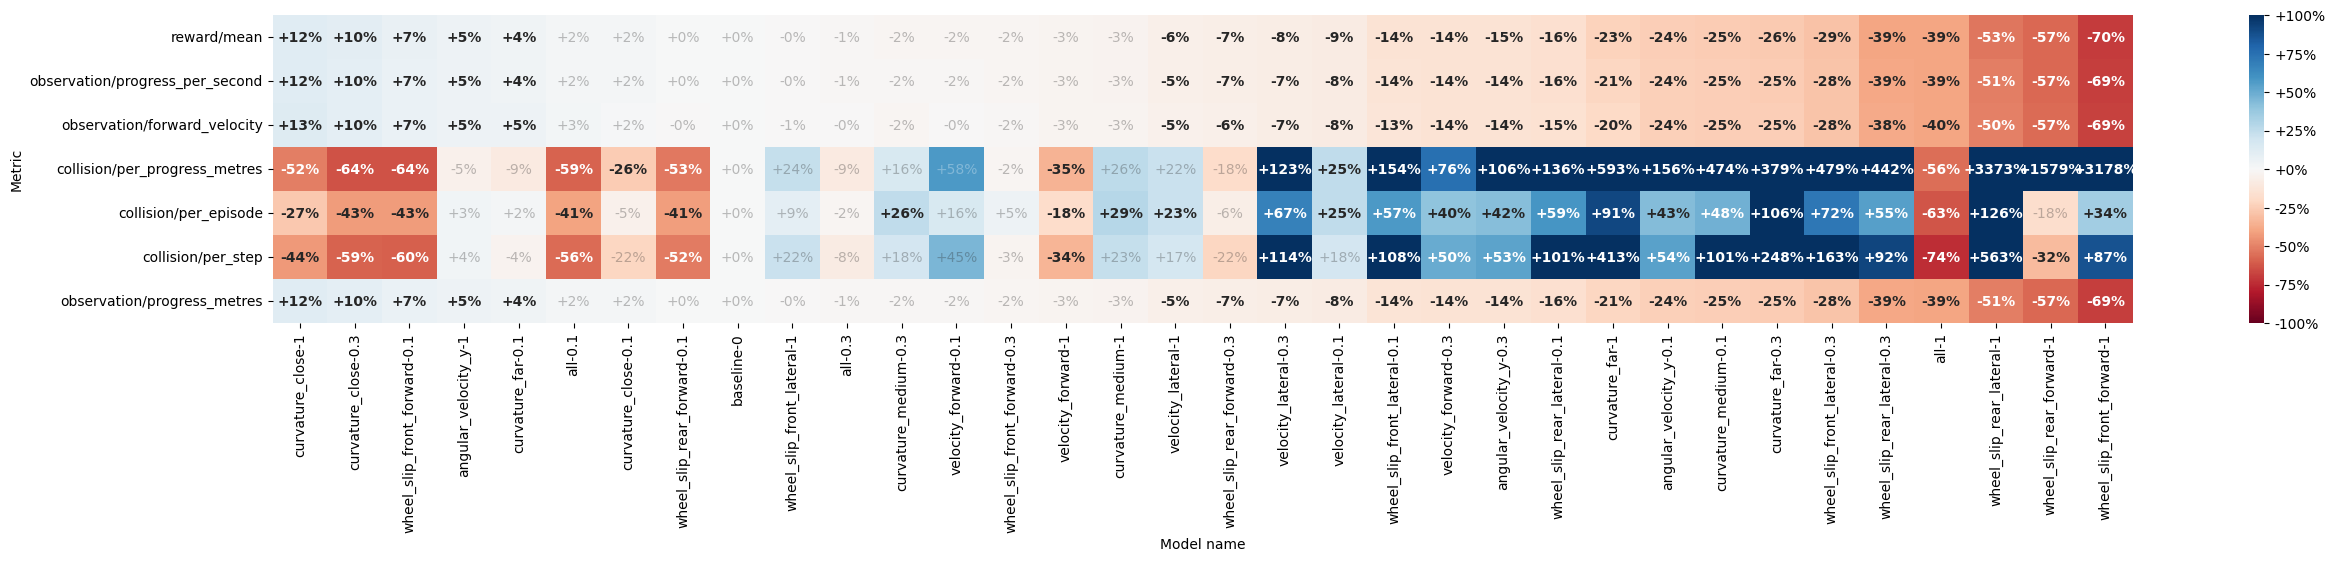

In [12]:
ALPHA = 0.5

to_show = last_50_means.groupby(["run_category", "aux_weight"])[IMPORTANT_STATS].mean().sort_values("reward/mean", ascending=False)
baseline = to_show.loc["baseline"].squeeze()

to_show = to_show.div(baseline, axis=1) - 1

sig = (last_50_means_ttest_results < ALPHA).T.reindex(
    index=to_show.T.index, columns=to_show.T.columns, fill_value=False
)

plt.figure(figsize=(30, 4))

ax = sns.heatmap(
    to_show.T,
    annot=True,
    fmt="+.0%",
    cmap="RdBu",
    center=0,
    vmax=1.0,
    vmin=-1.0,
    cbar_kws={"format": FuncFormatter(lambda x, _: f"{x:+.0%}")},
)
ax.set(xlabel="Model name", ylabel="Metric")

for t in ax.texts:
    x, y = t.get_position()
    if sig.iat[int(y - 0.5), int(x - 0.5)]:
        t.set_fontweight("bold")
    else:
        t.set_alpha(0.3)

plt.savefig("results/figures/last_50_means_heatmap.pdf", bbox_inches="tight")

In [13]:
to_show

tag                                  reward/mean  \
run_category             aux_weight                
curvature_close          1              0.124469   
                         0.3            0.102260   
wheel_slip_front_forward 0.1            0.071853   
angular_velocity_y       1              0.051617   
curvature_far            0.1            0.044511   
all                      0.1            0.022242   
curvature_close          0.1            0.020327   
wheel_slip_rear_forward  0.1            0.004245   
baseline                 0              0.000000   
wheel_slip_front_lateral 1             -0.004762   
all                      0.3           -0.010467   
curvature_medium         0.3           -0.016050   
velocity_forward         0.1           -0.016932   
wheel_slip_front_forward 0.3           -0.020277   
velocity_forward         1             -0.025441   
curvature_medium         1             -0.033085   
velocity_lateral         1             -0.055523   
wheel_slip_rear_forward  0.3           -0.066003   
velocity_lateral         0.3           -0.077396   
                         0.1           -0.085433   
wheel_slip_front_lateral 0.1           -0.141427   
velocity_forward         0.3           -0.144001   
angular_velocity_y       0.3           -0.147080   
wheel_slip_rear_lateral  0.1           -0.161175   
curvature_far            1             -0.228798   
angular_velocity_y       0.1           -0.243485   
curvature_medium         0.1           -0.253221   
curvature_far            0.3           -0.263342   
wheel_slip_front_lateral 0.3           -0.290622   
wheel_slip_rear_lateral  0.3           -0.392710   
all                      1             -0.393544   
wheel_slip_rear_lateral  1             -0.534120   
wheel_slip_rear_forward  1             -0.572801   
wheel_slip_front_forward 1             -0.699766   

tag                                  observation/progress_per_second  \
run_category             aux_weight                                    
curvature_close          1                                  0.122565   
                         0.3                                0.099912   
wheel_slip_front_forward 0.1                                0.069593   
angular_velocity_y       1                                  0.051532   
curvature_far            0.1                                0.044206   
all                      0.1                                0.020246   
curvature_close          0.1                                0.019516   
wheel_slip_rear_forward  0.1                                0.002514   
baseline                 0                                  0.000000   
wheel_slip_front_lateral 1                                 -0.004024   
all                      0.3                               -0.010813   
curvature_medium         0.3                               -0.015314   
velocity_forward         0.1                               -0.015037   
wheel_slip_front_forward 0.3                               -0.020288   
velocity_forward         1                                 -0.026548   
curvature_medium         1                                 -0.032256   
velocity_lateral         1                                 -0.054817   
wheel_slip_rear_forward  0.3                               -0.066475   
velocity_lateral         0.3                               -0.073344   
                         0.1                               -0.084534   
wheel_slip_front_lateral 0.1                               -0.137239   
velocity_forward         0.3                               -0.141834   
angular_velocity_y       0.3                               -0.144727   
wheel_slip_rear_lateral  0.1                               -0.157192   
curvature_far            1                                 -0.214114   
angular_velocity_y       0.1                               -0.240911   
curvature_medium         0.1                               -0.248965   
curvature_far            0.3           

In [14]:
to_show = last_50_means.groupby(["run_category", "aux_weight"])[IMPORTANT_STATS].mean().reset_index()
to_show

tag,run_category,aux_weight,reward/mean,observation/progress_per_second,observation/forward_velocity,collision/per_progress_metres,collision/per_episode,collision/per_step,observation/progress_metres
0,all,0.1,0.168372,4.215852,3.944799,0.001391,0.215592,0.000234,0.168634
1,all,0.3,0.162985,4.087512,3.834530,0.003063,0.356295,0.000493,0.163500
2,all,1,0.099889,2.501005,2.316751,0.001487,0.133365,0.000141,0.100040
3,angular_velocity_y,0.1,0.124605,3.136703,2.935268,0.008636,0.519337,0.000828,0.125468
4,angular_velocity_y,0.3,0.140483,3.534156,3.294647,0.006928,0.516269,0.000823,0.141366
5,angular_velocity_y,1,0.173210,4.345133,4.057343,0.003187,0.374957,0.000556,0.173805
6,baseline,0,0.164709,4.132194,3.848117,0.003369,0.362828,0.000537,0.165288
7,curvature_close,0.1,0.168057,4.212840,3.906240,0.002501,0.343210,0.000421,0.168514
8,curvature_close,0.3,0.181552,4.545051,4.236045,0.001214,0.207149,0.000221,0.181802
9,curvature_close,1,0.185210,4.638655,4.329249,0.001634,0.264505,0.000303,0.185546


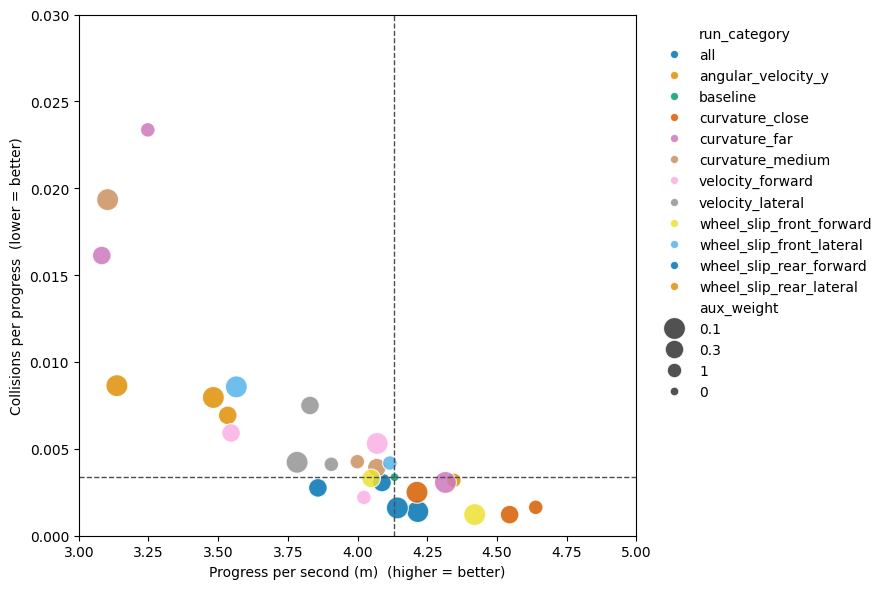

In [22]:
x_col = "observation/progress_per_second"
y_col = "collision/per_progress_metres"

baseline = to_show[to_show["run_category"] == "baseline"]
bx, by = baseline[x_col].mean(), baseline[y_col].mean()

fig, ax = plt.subplots(figsize=(9, 6))

sns.scatterplot(
    data=to_show,
    x=x_col,
    y=y_col,
    hue="run_category",
    size="aux_weight",
    sizes=(40, 250),
    palette="colorblind",
    alpha=0.85,
    edgecolor="white",
    legend="full",
    ax=ax,
).set()

# Baseline reference crosshair (dark grey so it doesn't clash with the palette)
ax.axhline(by, color="0.3", ls="--", lw=1)
ax.axvline(bx, color="0.3", ls="--", lw=1)
ax.annotate("baseline mean", (0.2, by), xytext=(-4, 5),
            textcoords="offset points", ha="right", fontsize=9, color="0.3")

ax.set(
    xlim=(3, 5),
    ylim=(0, 0.03),
    xlabel="Progress per second (m)  (higher = better)",
    ylabel="Collisions per progress  (lower = better)",
)

ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.tight_layout()
plt.savefig("results/figures/progress_vs_collision.pdf", bbox_inches="tight")